# Interpreta un banco de flotación como respuesta cinética

**Pregunta:** ¿Cómo producen medidas distintas de recuperación las tasas batch por clase y la residencia de un banco continuo?

Nivel: 1. Requisitos previos: Ninguno; comienza aquí. Tiempo de lectura: 18 minutos.

## Objetivos

Ejecuta el rougher Cu-Mo y distingue su curva batch virtual de la respuesta del banco alimentado de forma continua. Comprende por qué recuperación versus tiempo es una respuesta de proceso, no una animación decorativa.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 1 sobre 02-flotation, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; escenario Cu-Mo de autoría propia en `data/derived/cases/copper_molybdenum.json`, licencia MIT del proyecto. El motor genera la curva cinética; no se midió en laboratorio ni planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

OreFlow agrega tasas por clase mediante $R_b(t)=\sum_j c_jx_j(1-e^{-k_jt})/\sum_j c_jx_j$. Un banco continuo tiene otra distribución temporal y se calcula por separado. Llama a `simulate` y al constructor `trace` de producción.

Selecciona un caso Cu-Mo de autoría propia y ejecuta los mismos métodos de circuito y trace del pipeline de datos OreFlow.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
from pipeline.engine.trace import trace

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == "copper_molybdenum")
result = simulate(case.ore, case.plant, case.nominal)
record = trace(result, case.nominal, case.plant.family)
kinetics = record["methods"]["kinetics"]
print("familia:", record["family"], "| status:", kinetics["status"])
print("bank residence (min):", round(kinetics["bank"]["residence_min"], 2))
print("engine rougher recuperación (%):", round(kinetics["bank"]["engine_rougher_pct"], 2))


familia: rougher | status: computed
bank residence (min): 29.16
engine rougher recuperación (%): 94.01


Grafica la recuperación batch contra el tiempo y la recuperación del banco contra la posición de celda; los ejes x representan residencias distintas.

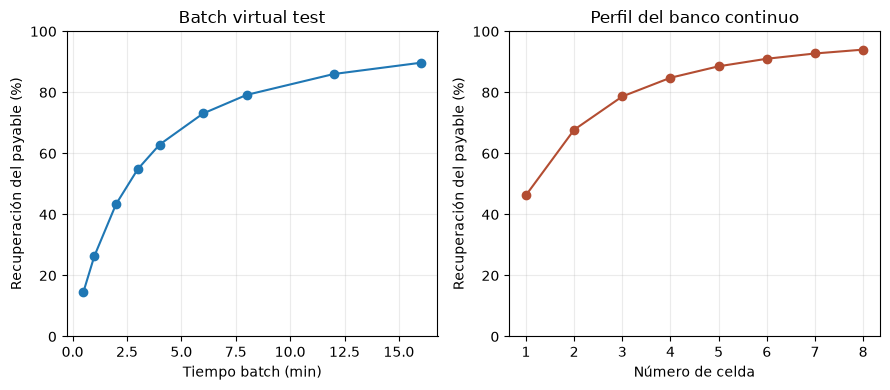

In [3]:
# Grafica la recuperación batch contra el tiempo y la recuperación del banco contra la posición de
# celda; los ejes x representan residencias distintas.
bank = record["curves"]["bank_profile"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].plot(kinetics["times_min"], kinetics["batch_recovery_pct"], "o-", label="Batch virtual")
axes[0].set(
    xlabel="Tiempo batch (min)", ylabel="Recuperación del payable (%)", title="Batch virtual test"
)
axes[1].plot([v["cell"] for v in bank], [100 * v["recovery"] for v in bank], "o-", color="#b34d32")
axes[1].set(
    xlabel="Número de celda",
    ylabel="Recuperación del payable (%)",
    title="Perfil del banco continuo",
)
for ax in axes:
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.25)
fig.tight_layout()


La figura 11 de nivel 1 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 11 de nivel 1 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 11 de nivel 1 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 11 solo guía la comparación.

Lee juntos alimentación rougher, concentrado y relave. Ley y recuperación responden preguntas distintas.

In [4]:
# Lee juntos alimentación rougher, concentrado y relave.
streams = record["streams"]
rows = [
    (name, streams[name]["solids_tph"], streams[name]["grades"][kinetics["species"]])
    for name in ("rougher_feed", "rougher_concentrate", "rougher_tail")
    if name in streams
]
display(pd.DataFrame(rows, columns=["Flujo", "Sólidos (t/h)", f"{kinetics['species']} grade (%)"]))


,Flujo,Sólidos (t/h),Cu grade (%)
0,rougher_feed,687.297218,0.620996
1,rougher_concentrate,61.023570,6.574911
2,rougher_tail,626.273648,0.040852


En el caso de nivel 1 sobre 02 flotation, la corrida con 0.9× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 1 sobre 02 flotation, con 0.9× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [5]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 94.143
product P80 (µm): 150.0


En el caso de nivel 1 sobre 02 flotation, la corrida con 1.1× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 1 sobre 02 flotation, con 1.1× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_molybdenum")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 704.0
recovery (%): 92.753
product P80 (µm): 150.0


En la lección de nivel 1 sobre 02 flotation, la lectura del gráfico 1 considera en esta figura del nivel 1 sobre 02 flotation, compara la recuperación con el P80 de producto al variar el tratamiento. En la lección de nivel 1 sobre 02 flotation, la lectura del gráfico 2 considera los ejes separan unidades distintas, así que el cambio describe el caso de autoría propia y no una tendencia empírica de planta. En la lección de nivel 1 sobre 02 flotation, la lectura del gráfico 3 considera el punto nominal sirve como referencia para los ajustes vecinos. En la lección de nivel 1 sobre 02 flotation, la lectura del gráfico 4 considera en «Interpreta un banco de flotación como respuesta cinética», cada punto procede de una evaluación independiente del motor y las líneas solo guían la vista entre ajustes probados.

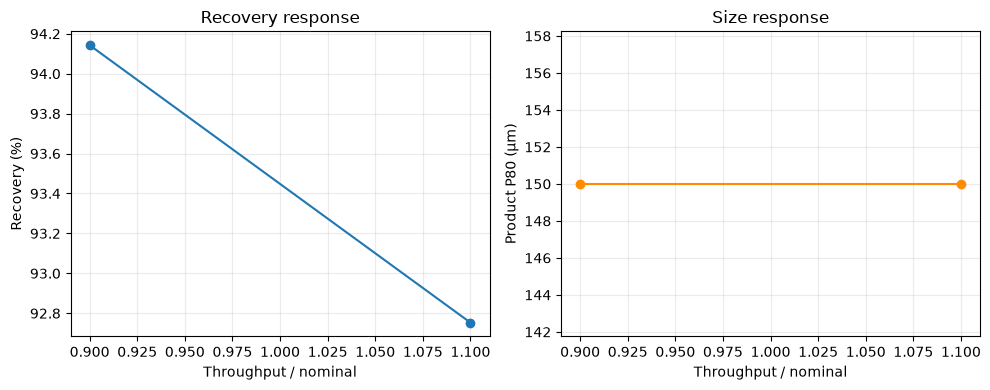

In [7]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.9, 1.1]
runs = [response_0_9, response_1_1]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


La figura 19 de nivel 1 sobre 02 flotation informa salidas de puntos operativos resueltos por separado. En la figura 19 de nivel 1 sobre 02 flotation, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 19 de nivel 1 sobre 02 flotation, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 19 solo guía la comparación.

En el nivel 1 de 02 flotation, la interpretación 1 es que la recuperación por flotación depende de los sólidos y minerales que entrega la molienda, los parámetros declarados de flotabilidad, la respuesta al colector y el tiempo de residencia disponible. En el nivel 1 de 02 flotation, la interpretación 2 es que un mayor tratamiento reduce el tiempo disponible por unidad de masa si el volumen de celdas no cambia. En el nivel 1 de 02 flotation, la interpretación 3 es que el modelo representa ese acoplamiento en el cálculo del banco. En el nivel 1 de 02 flotation, la interpretación 4 es que no anima partículas individuales ni infiere comportamiento de espuma desde una imagen. En el nivel 1 de 02 flotation, la interpretación 5 es que compara recuperación del mineral valioso con ley de concentrado y recuperación de agua, porque una mejora de recuperación también puede arrastrar más ganga o agua. En el nivel 1 de 02 flotation, la interpretación 6 es que formas cinéticas de primer orden, fracción rápida/lenta y tasas distribuidas pueden ajustar curvas batch similares y producir proyecciones distintas del banco. En el nivel 1 de 02 flotation, la interpretación 7 es que una referencia sintética de tasas exactas permite medir error de aproximación interno, pero no es un ensayo de laboratorio. En el nivel 1 de 02 flotation, la interpretación 8 es que transferir a una planta requiere muestras temporizadas, registros de reactivos, aire, geometría de celdas y una campaña independiente reservada.

## Resultados

**Respuesta:** En esta lección de nivel 1 sobre 02 flotation, el circuito ejecutado informa una recuperación de 94.01 por ciento para «Interpreta un banco de flotación como respuesta cinética» en el primer tratamiento controlado.

La curva batch es una prueba virtual generada por la distribución de tasas del motor; el perfil de banco aplica un modelo de residencia continua. La diferencia no es evidencia de planta. Ley del concentrado y recuperación son resultados distintos.

## Resumen

Ejecutaste el solver y revisaste sus respuestas batch y de banco simuladas. El registro no es información de laboratorio, y recorrer la flowsheet no equivale al tiempo físico de planta.

## Referencias

- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3
- https://doi.org/10.1016/0301-7516(81)90019-3